# Day 7 - Exploratory Data Analysis of Mine/Industrial Safety and Incidents

Keselamatan kerja (K3) adalah prioritas utama di industri tambang & pengeboran.

Menganalisis **data insiden** membantu menemukan pola:
- jenis cedera apa yang paling sering,
- bagian tubuh mana yang paling berisiko,
- kapan insiden memuncak.

Pada Notebook ini saya akan mengeksplorasi catatan kecelakaan industri (termasuk pengeboran/rig) untuk menghasilkan wawasan K3.

🎯 **Tujuan Pembelajaran**
> - Menganalisis **data kategorikal** insiden dengan `value_counts`.
> - Mengurutkan & memvisualisasikan kategori tersering (bar chart).
> - Mengekstrak tren waktu dari `Event Date`.
> - Menerjemahkan pola data menjadi **rekomendasi keselamatan**.

## About the Dataset

**OSHA Accident and Injury Data (2015–2017)** — catatan resmi insiden industri di AS, termasuk
sektor pengeboran & konstruksi berat yang relevan dengan pertambangan.

- **Sumber:** [Kaggle — ruqaiyaship/osha-accident-and-injury-data-1517](https://www.kaggle.com/datasets/ruqaiyaship/osha-accident-and-injury-data-1517)
- **Ukuran:** 4.847 baris × 29 kolom

| Kolom | Arti |
|-------|------|
| `Degree of Injury` | Tingkat keparahan (fatal, rawat inap, dll.) |
| `Nature of Injury` | Sifat cedera (patah, amputasi, luka bakar…) |
| `Part of Body` | Bagian tubuh yang cedera |
| `Event type` | Jenis kejadian pemicu |
| `Construction End Use` | Konteks/penggunaan lokasi |
| `Event Date` | Tanggal kejadian |

*Analisis ini bertujuan **mencegah** — mengenali risiko terbesar agar sumber daya K3 diarahkan tepat.*

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Import The Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d ruqaiyaship/osha-accident-and-injury-data-1517
!unzip osha-accident-and-injury-data-1517.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/ruqaiyaship/osha-accident-and-injury-data-1517
License(s): unknown
100% 869k/869k [00:00<00:00, 95.1MB/s]

Archive:  osha-accident-and-injury-data-1517.zip
  inflating: OSHA HSE DATA_ALL ABSTRACTS 15-17_FINAL.csv  


## Initial Exploration

In [3]:
df = pd.read_csv('/content/OSHA HSE DATA_ALL ABSTRACTS 15-17_FINAL.csv')
df.head()

,summary_nr,Event Date,Abstract Text,Event Description,Event Keywords,con_end,Construction End Use,build_stor,Building Stories,proj_cost,...,Event type,evn_factor,Environmental Factor,hum_factor,Human Factor,task_assigned,Task Assigned,hazsub,fat_cause,fall_ht
0,220982664,8/10/2017,"At 9:00 a.m. on August 10, 2017, an employee w...",EMPLOYEE'S FINGERS AMPUTATED WHILE OPERATING A...,"FINGER,MECHANICAL POWER PRESS,AMPUTATION,GUARD",0,,0,,0,...,Caught in or between,2,Catch Point/Puncture Action,14,Other,1,Regularly Assigned,0,0,0
1,220973937,7/17/2017,"At 9:45 a.m. on July 17, 2017, an employee was...",EMPLOYEE'S FINGER IS CAUGHT IN DRILL AND IS AM...,"CAUGHT IN,DRIVE SHAFT,RESIDENTIAL CONSTRUCTION...",H,Other building,1,1,0,...,Caught in or between,18,Other,10,Position Inappropriate For Task,1,Regularly Assigned,0,0,0
2,220967632,6/30/2017,"At 7:30 a.m. on June 30, 2017, an employee was...",EMPLOYEE IS HOSPITALIZED AFTER BEING INJURED I...,"AMPUTATED,EXPLOSION,FIREWORKS",0,,0,,0,...,Other,18,Other,4,Malfunction In Securing/Warning Op,2,Not Regularly Assigned,0,0,0
3,220969901,6/30/2017,"At 2:00 p.m. on June 30, 2017, an employee was...",EMPLOYEE FALLS FROM ROOF AND IS INJURED,"RIB,ROOF,HEAD,FALL PROTECTION,FALL,COLLARBONE,...",C,Commercial building,1,1,D,...,Fall (from elevation),13,Work-Surface/Facility-Layout Condition,14,Other,1,Regularly Assigned,0,15,0
4,220977748,6/23/2017,"At 12:20 p.m. on June 23, 2017, an employee wa...",EMPLOYEE IS STRUCK BY PLYWOOD WHILE UNLOADING ...,"STRUCK BY,TRUCK,BRAIN,NECK,FRACTURE,UNSTABLE LOAD",0,,0,,0,...,Struck-by,6,Overhead Moving/Falling Object Action,15,Insufficient/Lack/Housekeeping Program,1,Regularly Assigned,0,0,0


In [4]:
# Kolom yang kita fokuskan untuk analisis K3
fokus = ["Degree of Injury", "Nature of Injury", "Part of Body", "Event type",
         "Construction End Use", "Event Date"]

fokus = [k for k in fokus if k in df.columns]
print("Kolom fokus tersedia:", fokus)
df[fokus].isnull().mean().mul(100).round(1)

Kolom fokus tersedia: ['Degree of Injury', 'Nature of Injury', 'Part of Body', 'Event type', 'Construction End Use', 'Event Date']


,0
Degree of Injury,0.0
Nature of Injury,0.0
Part of Body,0.0
Event type,0.0
Construction End Use,0.0
Event Date,0.0


**Interpretation:**


**Keenam kolom fokus K3 100% terisi (tidak ada nilai kosong/`NaN`)** dan siap dianalisis.

Hal yang tetap perlu dicek sebelum lanjut:

* **Label pengganti:** pastikan tidak ada teks seperti `"Unknown"`, `"N/A"`, atau string kosong `""` yang sebenarnya berarti data tidak diketahui.
* **Format tanggal (`Event Date`):** pastikan sudah bertipe tanggal (`datetime`) dan rentangnya wajar.
* **Konsistensi kategori:** cek apakah ada penulisan ganda atau *typo* pada tiap kolom.

In [9]:
df["Event Date"] = pd.to_datetime(df["Event Date"], errors="coerce")

In [10]:
df[fokus].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4847 entries, 0 to 4846
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Degree of Injury      4847 non-null   object        
 1   Nature of Injury      4845 non-null   object        
 2   Part of Body          4845 non-null   object        
 3   Event type            4845 non-null   object        
 4   Construction End Use  4847 non-null   object        
 5   Event Date            4847 non-null   datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 227.3+ KB


In [11]:
kolom_cek = ["Nature of Injury", "Part of Body", "Event type"]
df[df[kolom_cek].isnull().any(axis=1)]

,summary_nr,Event Date,Abstract Text,Event Description,Event Keywords,con_end,Construction End Use,build_stor,Building Stories,proj_cost,...,Event type,evn_factor,Environmental Factor,hum_factor,Human Factor,task_assigned,Task Assigned,hazsub,fat_cause,fall_ht
1294,220934970,2017-02-22,"At approximately 1:30 p.m. on February 22, 201...",NO RECORDABLE INJURY,"BACKING UP,POWERED INDUSTRIAL VEHICLE",0,,0,,0,...,NaN,0,NaN,0,NaN,2,Not Regularly Assigned,0,0,0
1660,220936678,2017-02-03,"At 12:00 a.m. on February 3, 2017, employees w...",EMPLOYEES EXPOSED TO ASBESTOS WHILE CLEANING U...,"NON-PEL OVEREXPOSURE,ASBESTOS",0,,0,,0,...,NaN,0,NaN,0,NaN,2,Not Regularly Assigned,0,0,0


In [12]:
df = df.drop(index=[1294, 1660])

In [13]:
df[fokus].info()

<class 'pandas.core.frame.DataFrame'>
Index: 4845 entries, 0 to 4846
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Degree of Injury      4845 non-null   object        
 1   Nature of Injury      4845 non-null   object        
 2   Part of Body          4845 non-null   object        
 3   Event type            4845 non-null   object        
 4   Construction End Use  4845 non-null   object        
 5   Event Date            4845 non-null   datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 265.0+ KB


**Interpretation:**

DataFrame kini bersih dan lengkap dengan **4.845 baris** dan **6 kolom** (`0` nilai kosong/`NaN` di seluruh kolom).

### Ringkasan Kondisi Data Saat Ini

* **Kelengkapan 100% (`4845 non-null`):** seluruh kolom (`Degree of Injury`, `Nature of Injury`, `Part of Body`, `Event type`, `Construction End Use`, dan `Event Date`) sudah terisi penuh.
* **Tipe data siap pakai:** `Event Date` bertipe `datetime64[ns]`, sedangkan 5 kolom kategorikal bertipe `object`.
* **Struktur indeks:** indeks masih mempertahankan nomor asli (`0` sampai `4846`, dengan `1294` dan `1660` terhapus) dan ukuran memori **265.0+ KB**.

## Exploratory Data Analysis & Visualization

### a) Severity of injury (bar)

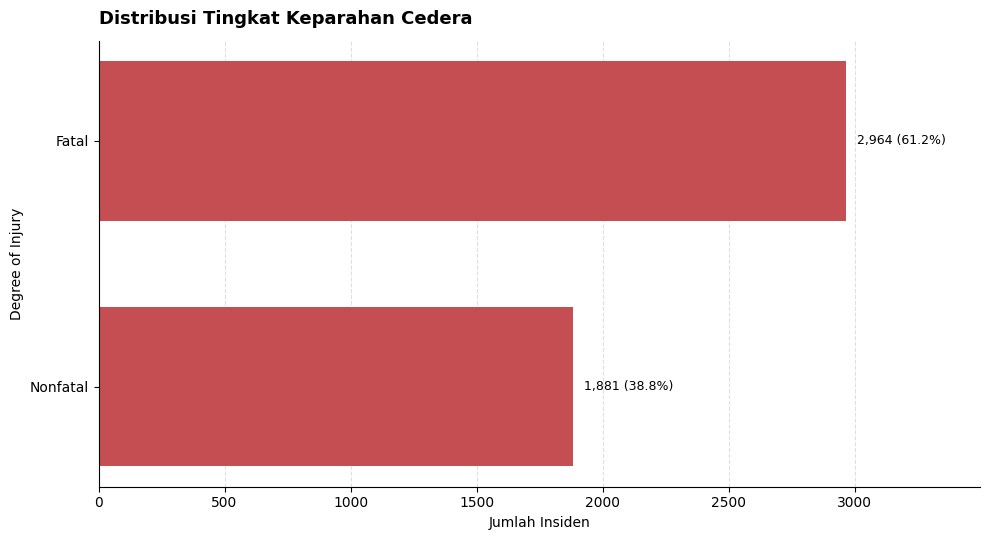

In [14]:
deg = df["Degree of Injury"].value_counts().head(8).sort_values()
total = len(df)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(deg.index, deg.values, color="#C44E52", height=0.65)

ax.set_title("Distribusi Tingkat Keparahan Cedera", loc="left", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Jumlah Insiden")
ax.set_ylabel("Degree of Injury")
ax.set_xlim(0, deg.max() * 1.18)  # beri ruang agar teks anotasi tidak terpotong
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    val = int(bar.get_width())
    pct = val / total * 100
    ax.text(
        val + deg.max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,} ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

**Interpretation:**

Dari total **4.845 insiden** pada data ini, **sebagian besar kasus berakibat fatal**:

* **Fatal:** **2.964 insiden (61,2%)** — lebih dari separuh kejadian tercatat berujung kematian.


* **Nonfatal:** **1.881 insiden (38,8%)** — sisanya merupakan cedera tidak fatal.


**Intinya:** insiden **Fatal** lebih banyak terjadi dibanding **Nonfatal** (selisih **1.083 kasus** atau sekitar **22,4 poin persentase**), sehingga pencegahan risiko berat/mematikan menjadi prioritas utama dari data ini.

### b) Body parts most frequently injured (top-10 bar)

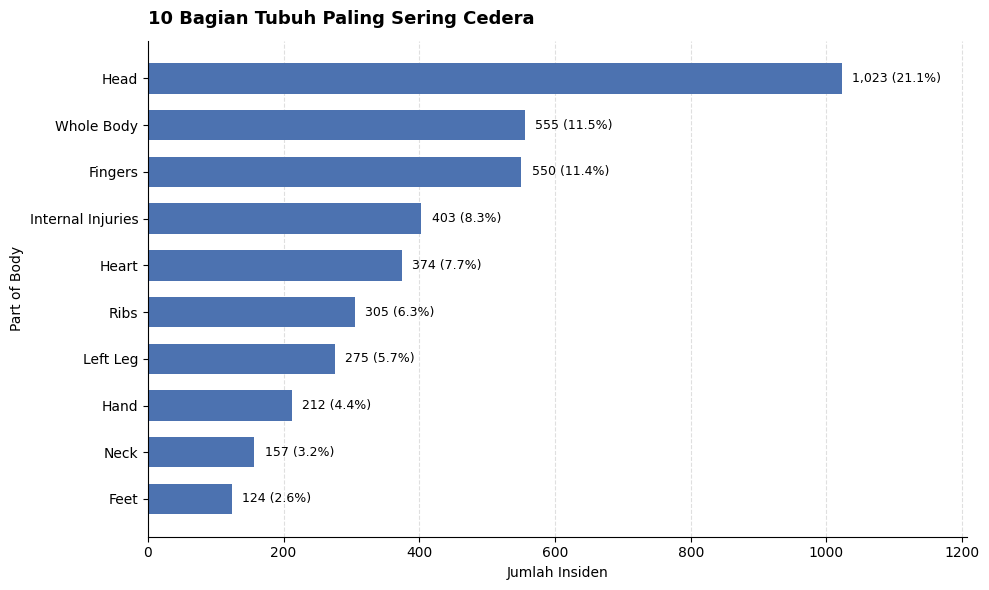

In [15]:
body = df["Part of Body"].value_counts().head(10).sort_values()
total = len(df)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(body.index, body.values, color="#4C72B0", height=0.65)

ax.set_title("10 Bagian Tubuh Paling Sering Cedera", loc="left", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Jumlah Insiden")
ax.set_ylabel("Part of Body")
ax.set_xlim(0, body.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    val = int(bar.get_width())
    pct = val / total * 100
    ax.text(
        val + body.max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,} ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

**Interpretation:**

Dari grafik **10 Bagian Tubuh Paling Sering Cedera** tersebut, **Head (Kepala)** menempati urutan teratas dengan jumlah jauh melampaui bagian tubuh lainnya.

### Poin Utama

* **Kepala paling dominan:**
  - **Head** tercatat sebanyak **1.023 insiden (21,1%)**—hampir dua kali lipat dari posisi kedua.


* **Peringkat 2 & 3 hampir imbang:**
  - **Whole Body** (**555 insiden / 11,5%**) dan **Fingers** (**550 insiden / 11,4%**) berada di urutan berikutnya dengan selisih sangat tipis.


* **Cedera organ vital & torso signifikan:**
  - **Internal Injuries** (**403 / 8,3%**), **Heart** (**374 / 7,7%**), dan **Ribs** (**305 / 6,3%**) masuk dalam 6 besar, sejalan dengan tingginya proporsi insiden fatal pada analisis sebelumnya.


* **Anggota gerak & leher:**
  - **Left Leg** (**275 / 5,7%**), **Hand** (**212 / 4,4%**), **Neck** (**157 / 3,2%**), dan **Feet** (**124 / 2,6%**) melengkapi daftar 10 besar.



**Intinya:**
  - perlindungan kepala (`Head`), keselamatan seluruh tubuh (`Whole Body`), serta pencegahan cedera jari/tangan (`Fingers`, `Hand`) dan benturan/cedera internal (`Internal Injuries`, `Heart`, `Ribs`) merupakan area prioritas utama pada data insiden ini.

### c) Most frequent type of injury (bar chart)

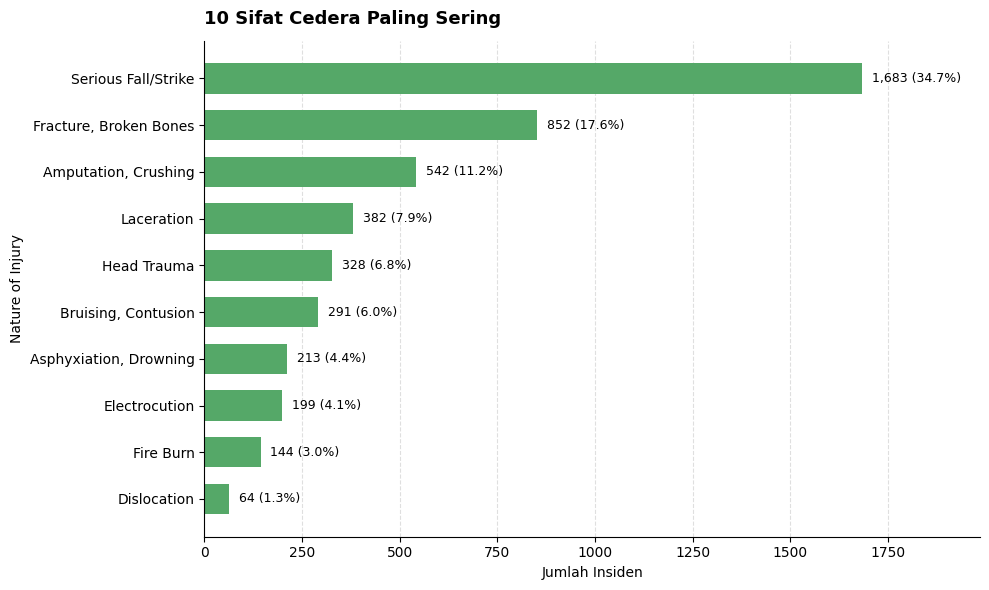

In [16]:
nat = df["Nature of Injury"].value_counts().head(10).sort_values()
total = len(df)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(nat.index, nat.values, color="#55A868", height=0.65)

ax.set_title("10 Sifat Cedera Paling Sering", loc="left", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Jumlah Insiden")
ax.set_ylabel("Nature of Injury")
ax.set_xlim(0, nat.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for bar in bars:
    val = int(bar.get_width())
    pct = val / total * 100
    ax.text(
        val + nat.max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,} ({pct:.1f}%)",
        va="center",
        ha="left",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

**Interpretation:**

Dari grafik **10 Sifat Cedera Paling Sering**, **Serious Fall/Strike** mendominasi jauh di posisi teratas.

Poin Utama

* **Jatuh/benturan serius paling dominan:**
  - **Serious Fall/Strike** mencapai **1.683 insiden (34,7%)**—hampir dua kali lipat dari peringkat kedua.


* **Patah tulang & cedera berat berikutnya:**
  - **Fracture, Broken Bones** (**852 / 17,6%**) dan **Amputation, Crushing** (**542 / 11,2%**) berada di urutan ke-2 dan ke-3, menunjukkan banyak cedera berdampak struktural/berat.


* **Luka robek, trauma kepala, dan memar:**
  - **Laceration** (**382 / 7,9%**), **Head Trauma** (**328 / 6,8%**), dan **Bruising, Contusion** (**291 / 6,0%**) menyusul di kelompok menengah—sejalan dengan banyaknya cedera pada kepala dan anggota tubuh pada grafik sebelumnya.


* **Risiko spesifik berkonsekuensi tinggi:**
  - **Asphyxiation, Drowning** (**213 / 4,4%**), **Electrocution** (**199 / 4,1%**), **Fire Burn** (**144 / 3,0%**), dan **Dislocation** (**64 / 1,3%**) melengkapi 10 besar dengan jumlah lebih kecil namun sering berkaitan dengan insiden berisiko tinggi.



**Intinya:**
  - Pencegahan jatuh/benturan keras (**Serious Fall/Strike**), patah tulang (**Fracture, Broken Bones**), dan amputasi/remuk (**Amputation, Crushing**) mencakup lebih dari separuh total kasus dan menjadi fokus utama pengendalian risiko kerja pada data ini.


### d) Monthly incident trend (line)

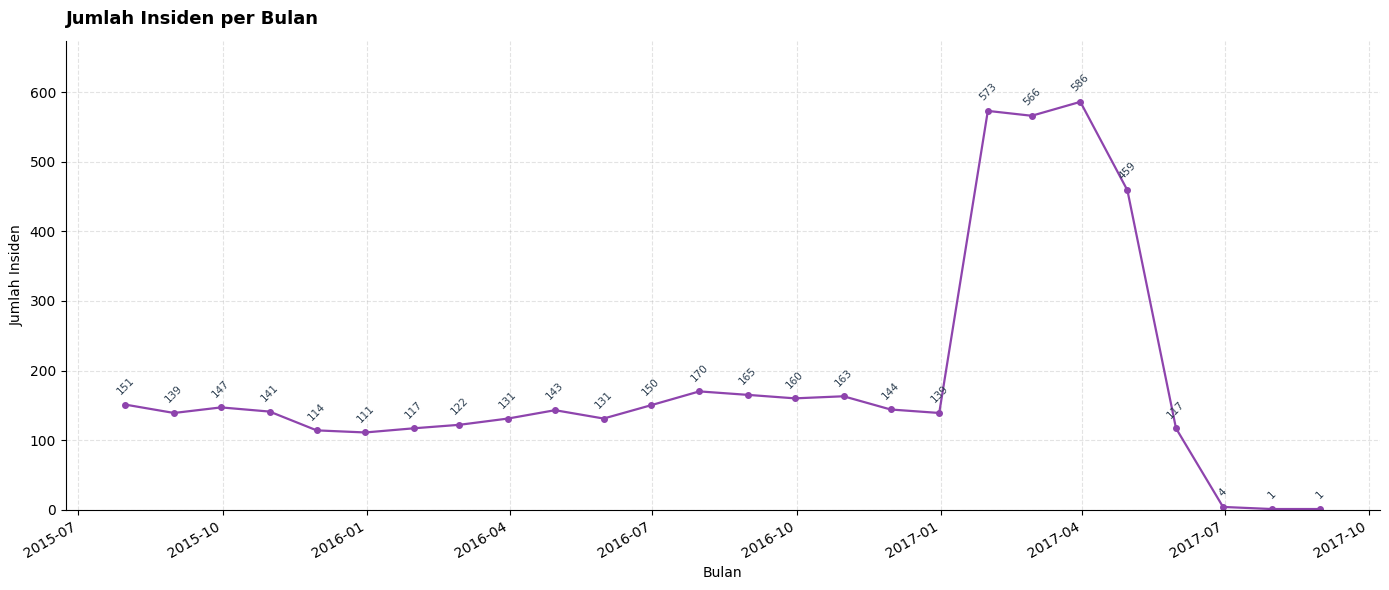

In [17]:
per_bulan = df.dropna(subset=["Event Date"]).set_index("Event Date").resample("ME").size()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    per_bulan.index,
    per_bulan.values,
    marker="o",
    markersize=4,
    linewidth=1.6,
    color="#8E44AD",
)

ax.set_title("Jumlah Insiden per Bulan", loc="left", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Insiden")
ax.set_ylim(0, per_bulan.max() * 1.15)  # ruang atas agar label angka tidak menabrak tepi
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Anotasi kecil di atas tiap titik; jika rentang bulan panjang (mis. > 24 titik),
# rotasi label membantu mencegah teks saling tindih
rotation = 45 if len(per_bulan) > 24 else 0
for dt, val in per_bulan.items():
    ax.annotate(
        f"{int(val)}",
        xy=(dt, val),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=7.5,
        rotation=rotation,
        color="#2C3E50",
    )

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Interpretation:**

Dari grafik **Jumlah Insiden per Bulan** (sekitar pertengahan 2015 hingga akhir 2017), pola kejadian terbagi menjadi tiga fase yang sangat kontras.

Pola Utama Tren Bulanan

* **Fase stabil & rendah (pertengahan 2015 – awal 2017):**
  - jumlah insiden berada di kisaran **111 hingga 170 kasus per bulan** (terendah **111** di awal 2016, puncak ringan **170** di pertengahan 2016, lalu **139** di awal 2017).


* **Lonjakan tajam (sekitar Februari – Mei 2017):**
  - angka melonjak drastis menjadi **573**, **566**, puncaknya **586**, lalu **459**—lebih dari tiga kali lipat rata-rata periode sebelumnya.


* **Penurunan drastis di akhir periode (pertengahan – akhir 2017):**
  - turun ke **117**, lalu anjlok menjadi **4**, **1**, dan **1**.



Catatan Analisis penting

Lonjakan besar di awal–pertengahan 2017 dan angka yang nyaris nol di akhir 2017 **tidak otomatis berarti risiko di lapangan berubah seketika**—sering kali dipengaruhi oleh *batch* pelaporan/pengumpulan data, perubahan cakupan sumber data, atau potongan waktu dataset (*cutoff* penarikan data). Sebaiknya cek dulu apakah lonjakan 2017 berasal dari satu jenis kejadian, proyek, atau periode input tertentu sebelum menyimpulkan tren waktu.

## Conclusions & Insights



1. Tingginya Fatalitas (High Gravity of Incidents)
    * **Wawasan:** Sebanyak **61,2% (2.964 insiden)** berujung fatal. Hal ini menunjukkan bahwa dataset didominasi oleh kecelakaan berskala berat hingga sangat fatal.
    * **Rekomendasi:** Fokus utama program keselamatan kerja harus diarahkan pada mitigasi risiko tinggi (*high-risk tasks*) yang berpotensi menyebabkan kematian (*fatalities*), bukan sekadar penanganan cedera ringan.

2. Perlindungan Kepala adalah Prioritas Mutlak
    * **Wawasan:** Kepala (**Head**) merupakan bagian tubuh yang paling sering cedera dengan **1.023 kasus (21,1%)**, disusul oleh seluruh tubuh (**Whole Body - 11,5%**) dan jari (**Fingers - 11,4%**).
    * **Rekomendasi:**
      - Penegakan disiplin penggunaan Helm Safety (PPE/APD) standar tinggi di area kerja.
      - Pemasangan jaring pengaman (*safety nets*) atau pelindung atas (*overhead protection*) di area konstruksi/pengeboran untuk mencegah benturan dari benda jatuh.
      - Penggunaan sarung tangan pelindung khusus untuk menekan angka cedera jari/tangan.

3. Kendalikan Bahaya Jatuh dan Benturan
   * **Wawasan:** Sifat cedera didominasi oleh **Serious Fall/Strike (34,7% / 1.683 kasus)** dan patah tulang (**Fracture/Broken Bones - 17,6%**).
   * **Rekomendasi:**
     - Implementasi sistem proteksi jatuh (*Fall Protection System*) yang ketat seperti penggunaan *full-body harness* untuk pekerjaan di ketinggian.
     - Pemeriksaan dan pemeliharaan rutin (*scaffolding*, tangga, dan platform kerja).
     - Penerapan prosedur penanganan material aman (*material handling*) guna mengurangi risiko pekerja terbentur atau tertimpa material berat.

4. Waspadai Anomali Data Bulanan
   * **Wawasan:** Tren bulanan menunjukkan lonjakan masif yang tidak biasa pada periode **Februari – Mei 2017**.
   * **Rekomendasi:** Perlu investigasi lebih lanjut untuk memverifikasi apakah lonjakan tersebut disebabkan oleh perubahan nyata di lapangan (misal: musim proyek padat karya) atau merupakan anomali administratif (perubahan metode input pelaporan/sinkronisasi database).


Berdasarkan hasil analisis data insiden OSHA (2015–2017) pada sel-sel sebelumnya, berikut adalah kesimpulan utama serta rekomendasi K3 (*Safety Recommendations*) yang dapat diambil:



1. **Tingginya Proporsi Kasus Fatal dalam Dataset**
    * **Wawasan:** Sebanyak **61,2% (2.964 insiden)** pada data insiden OSHA yang dianalisis berujung fatal. Angka ini mencerminkan dominasi kasus berdampak berat/mematikan di dalam dataset ini (bukan berarti proporsi seluruh kecelakaan kerja di lapangan pasti sama), sehingga alokasi upaya K3 perlu memprioritaskan pengendalian risiko tinggi (*high-risk controls*) tanpa mengabaikan penanganan cedera ringan agar tidak berkembang menjadi insiden lebih serius.
    * **Rekomendasi:**
      * Terapkan pengendalian risiko berlapis (*hierarchy of controls*) pada pekerjaan berisiko tinggi—mulai dari eliminasi/substitusi bahaya dan rekayasa teknis (*engineering controls*) sebelum mengandalkan APD.
      * Perketat izin kerja aman (*permit to work*), *job safety analysis* (JSA), dan pengawasan langsung pada aktivitas berdampak fatal.




2. **Perlindungan Kepala dan Tangan/Jari Menjadi Fokus Utama**
    * **Wawasan:** Bagian tubuh yang paling sering cedera adalah **Kepala (`Head`)** sebanyak **1.023 kasus (21,1%)**, diikuti **Seluruh Tubuh (`Whole Body`)** sebesar **11,5%** dan **Jari (`Fingers`)** sebesar **11,4%**.
    * **Rekomendasi:**
      * Utamakan pengendalian teknis di area kerja, seperti pemasangan pelindung atas (*overhead protection*), *safety nets*, *guardrails*, serta *machine guarding* pada peralatan bergerak/berputar.
      * Tegakkan penggunaan APD standar yang sesuai—seperti helm *safety* dan sarung tangan pelindung—sebagai lapisan perlindungan tambahan yang diperiksa rutin.




3. **Pengendalian Risiko Jatuh, Benturan, dan Cedera Struktural**
    * **Wawasan:** Sifat cedera terbanyak tercatat pada **Serious Fall/Strike** (**1.683 kasus / 34,7%**), disusul **Fracture, Broken Bones** (**17,6%**) dan **Amputation, Crushing** (**11,2%**).
    * **Rekomendasi:**
      * Terapkan sistem pencegahan dan penahan jatuh (*fall protection system*) yang ketat untuk pekerjaan di ketinggian, termasuk inspeksi rutin *scaffolding*, tangga, dan platform kerja.
      * Standarkan prosedur *lifting & material handling* serta pengaturan zona aman alat/material agar risiko tertimpa, terbentur, atau terjepit dapat ditekan.




4. **Verifikasi Anomali Tren Waktu Sebelum Menarik Kesimpulan Operasional**
    * **Wawasan:** Grafik bulanan memperlihatkan lonjakan tajam pada **Februari–Mei 2017**, lalu diikuti penurunan drastis hingga mendekati nol pada **pertengahan–akhir 2017**.
    * **Rekomendasi:**
      * Periksa apakah lonjakan awal–pertengahan 2017 dan penurunan tajam di akhir periode dipengaruhi oleh *batch* pelaporan, perubahan proses input/sinkronisasi data, atau batas penarikan data (*cutoff*), bukan semata perubahan kondisi lapangan.
      * Kaitkan analisis tren waktu dengan kolom `Event type` dan `Construction End Use` agar pola kejadian lebih mudah dipahami secara kontekstual.